# PS6: Facial emotion recognition with a CNN (CK+)
Dataset layout (Kaggle "CK+48"): CK+48/<emotion>/*.png
Emotions: anger, contempt, disgust, fear, happy, sadness, surprise. No separate test folder, so 20% is held out.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import tensorflow as tf
from sklearn.metrics import classification_report, confusion_matrix
from tensorflow import keras
from tensorflow.keras import layers

DATA_DIR = "../datasets/CK+48"
EPOCHS = 40
IMG = (48, 48)

In [2]:
train_ds = keras.utils.image_dataset_from_directory(
    DATA_DIR, color_mode="grayscale", image_size=IMG, batch_size=32,
    validation_split=0.2, subset="training", seed=42)
test_ds = keras.utils.image_dataset_from_directory(
    DATA_DIR, color_mode="grayscale", image_size=IMG, batch_size=32,
    validation_split=0.2, subset="validation", seed=42)
class_names = train_ds.class_names
print(class_names)

Found 981 files belonging to 7 classes.


Using 785 files for training.


Found 981 files belonging to 7 classes.


Using 196 files for validation.


['anger', 'contempt', 'disgust', 'fear', 'happy', 'sadness', 'surprise']


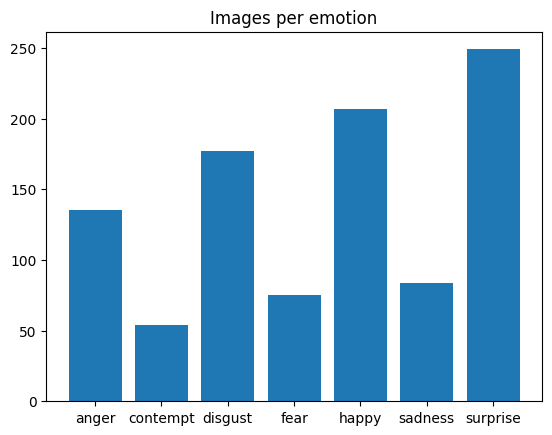

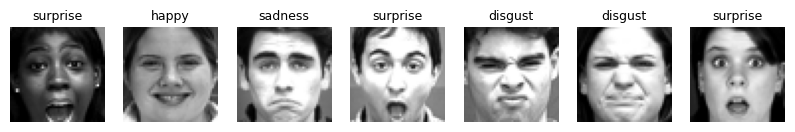

In [3]:
counts = [len(tf.io.gfile.listdir(f"{DATA_DIR}/{c}")) for c in class_names]
plt.bar(class_names, counts)
plt.title("Images per emotion")
plt.show()

plt.figure(figsize=(10, 3))
for images, labels in train_ds.take(1):
    for i in range(7):
        plt.subplot(1, 7, i + 1)
        plt.imshow(images[i].numpy().squeeze(), cmap="gray")
        plt.title(class_names[labels[i]], fontsize=9)
        plt.axis("off")
plt.show()

train_ds = train_ds.cache().prefetch(tf.data.AUTOTUNE)
test_ds = test_ds.cache()

In [4]:
model = keras.Sequential([
    layers.Input(IMG + (1,)),
    layers.Rescaling(1 / 255.0),
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.Conv2D(32, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(128, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(len(class_names), activation="softmax"),
])
model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 48, 48, 1)      │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 48, 48, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 24, 24, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 12, 12, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       589,952 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 683,527 (2.61 MB)

 Trainable params: 683,527 (2.61 MB)

 Non-trainable params: 0 (0.00 B)

In [5]:
history = model.fit(train_ds, validation_data=test_ds, epochs=EPOCHS, verbose=2)

Epoch 1/40


25/25 - 2s - 73ms/step - accuracy: 0.2535 - loss: 1.8608 - val_accuracy: 0.2449 - val_loss: 1.8141


Epoch 2/40


25/25 - 0s - 19ms/step - accuracy: 0.2510 - loss: 1.8229 - val_accuracy: 0.2449 - val_loss: 1.7466


Epoch 3/40


25/25 - 1s - 20ms/step - accuracy: 0.3567 - loss: 1.6709 - val_accuracy: 0.3724 - val_loss: 1.4665


... (70 outputs left out)

Epoch 39/40


25/25 - 0s - 20ms/step - accuracy: 0.8828 - loss: 0.3333 - val_accuracy: 0.8878 - val_loss: 0.3162


Epoch 40/40


25/25 - 1s - 20ms/step - accuracy: 0.8981 - loss: 0.3021 - val_accuracy: 0.9133 - val_loss: 0.2018


Test accuracy: 0.9133   Test loss: 0.2018


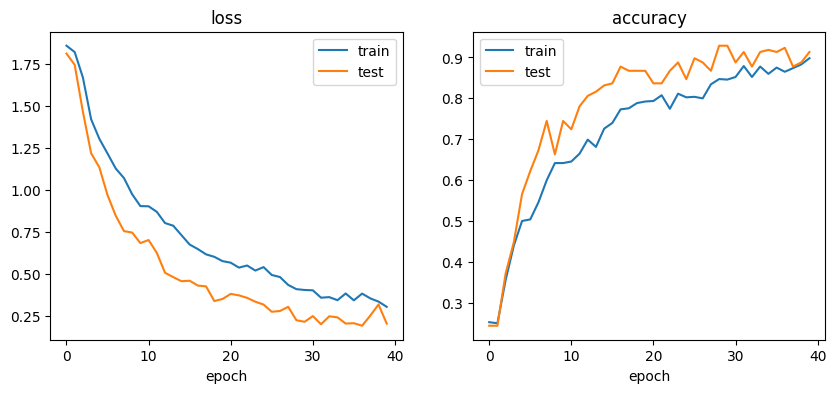

In [6]:
loss, acc = model.evaluate(test_ds, verbose=0)
print(f"Test accuracy: {acc:.4f}   Test loss: {loss:.4f}")

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for i, metric in enumerate(["loss", "accuracy"]):
    ax[i].plot(history.history[metric], label="train")
    ax[i].plot(history.history["val_" + metric], label="test")
    ax[i].set_title(metric)
    ax[i].set_xlabel("epoch")
    ax[i].legend()
plt.show()

              precision    recall  f1-score   support

       anger     0.8966    0.8387    0.8667        31
    contempt     0.7143    0.6250    0.6667         8
     disgust     1.0000    1.0000    1.0000        30
        fear     0.8333    0.9375    0.8824        16
       happy     1.0000    0.9545    0.9767        44
     sadness     0.6500    0.6842    0.6667        19
    surprise     0.9600    1.0000    0.9796        48

    accuracy                         0.9133       196
   macro avg     0.8649    0.8629    0.8627       196
weighted avg     0.9146    0.9133    0.9132       196



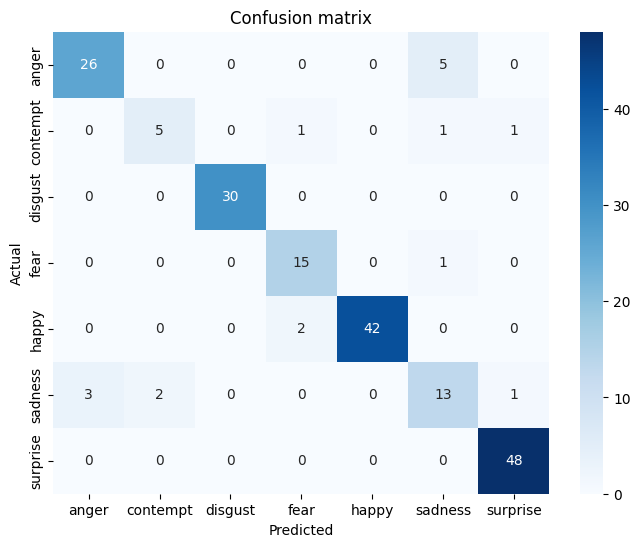

In [7]:
y_true, y_pred = [], []
for images, labels in test_ds:
    y_true.extend(labels.numpy())
    y_pred.extend(model.predict(images, verbose=0).argmax(axis=1))
print(classification_report(y_true, y_pred, labels=range(len(class_names)), target_names=class_names,
                            digits=4, zero_division=0))

plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix(y_true, y_pred, labels=range(len(class_names))), annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion matrix")
plt.show()

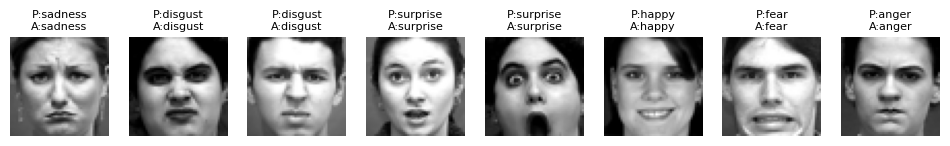

In [8]:
images, labels = next(iter(test_ds.unbatch().shuffle(500).batch(8)))
preds = model.predict(images, verbose=0).argmax(axis=1)
plt.figure(figsize=(12, 3))
for i in range(len(preds)):
    plt.subplot(1, 8, i + 1)
    plt.imshow(images[i].numpy().squeeze(), cmap="gray")
    plt.title(f"P:{class_names[preds[i]]}\nA:{class_names[labels[i]]}", fontsize=8)
    plt.axis("off")
plt.show()